## Used Car Price Prediction Using Regression model.

In this project, I explored used-car data and built regression models to predict selling prices.

I performed exploratory data analysis to examine how car prices varied by brand, model, year, kilometres travelled, fuel type and city. I then prepared the input features and compared Linear Regression, Random Forest and Gradient Boosting.

Random Forest performed best among the three tested models, achieving an MAE of ₹3.12 lakh, RMSE of ₹9.62 lakh and R² score of 0.725 on the test dataset.

I saved the selected model together with its preprocessing component and verified that the saved model reproduced the original test predictions.

Although Random Forest performed better than the other tested models, some predictions may still have large errors. Its performance should be evaluated further before using it to estimate prices for real-world buying or selling decisions.

In [94]:
## Importing the Librery.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Set the visualization style
sns.set_theme(style="whitegrid")


df = pd.read_csv("Dataset.csv")
print("Dataset Load Successfully")

Dataset Load Successfully


In [52]:
## Getting the First 5 Rows of dataset for insprection
df.head()

,Unnamed: 0,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city,...,new and less used,inv_car_price,inv_car_dist,inv_car_age,inv_brand,std_invprice,std_invdistance_travelled,std_invrank,best_buy1,best_buy2
0,0,0,2016,Honda,Honda Brio S MT,Brio,425000.0,9680.0,Petrol,Mumbai,...,0,2.352941e-06,0.000103,0.200000,0.142857,0.143417,0.035730,0.132143,677.134239,0.000000
1,1,1,2012,Nissan,Nissan Sunny XV Diesel,Sunny,325000.0,119120.0,Diesel,Mumbai,...,0,3.076923e-06,0.000008,0.111111,0.090909,0.188859,0.002496,0.079545,37.501318,0.000000
2,2,2,2017,Toyota,Toyota Fortuner 2.8 4x2 MT [2016-2020],Fortuner,2650000.0,64593.0,Diesel,Thane,...,0,3.773585e-07,0.000015,0.250000,1.000000,0.019416,0.004978,1.000000,96.646020,0.000000
3,3,3,2017,Mercedes-Benz,Mercedes-Benz E-Class E 220d Expression [2019-...,E-Class,4195000.0,25000.0,Diesel,Mumbai,...,1,2.383790e-07,0.000040,0.250000,0.500000,0.010692,0.013563,0.493750,71.604306,71.604306
4,4,4,2012,Hyundai,Hyundai Verna Fluidic 1.6 CRDi SX,Verna,475000.0,23800.0,Diesel,Mumbai,...,0,2.105263e-06,0.000042,0.111111,0.071429,0.127871,0.014269,0.059821,109.150857,0.000000


In [53]:
## Getting the Last 5 Rows of dataset for insprection
df.tail()

,Unnamed: 0,Id,year,brand,full_model_name,model_name,price,distance_travelled(kms),fuel_type,city,...,new and less used,inv_car_price,inv_car_dist,inv_car_age,inv_brand,std_invprice,std_invdistance_travelled,std_invrank,best_buy1,best_buy2
1720,1720,1720,2015,Hyundai,Hyundai Eon Era +,Eon,290000.0,38000.0,Petrol,Pune,...,0,3.448276e-06,0.000026,0.166667,0.071429,0.212168,0.008771,0.059821,111.327773,0.0
1721,1721,1721,2011,Bentley,Bentley Continental Flying Spur W12,Continental,7500000.0,36000.0,Petrol,Pune,...,0,1.333333e-07,0.000028,0.100000,0.022727,0.004099,0.009283,0.010511,0.399987,0.0
1722,1722,1722,2008,Mahindra-Renault,Mahindra-Renault Logan DLE 1.5 dci,Logan,185000.0,142522.0,Diesel,Pune,...,0,5.405405e-06,0.000007,0.076923,0.041667,0.335011,0.002014,0.029687,20.026662,0.0
1723,1723,1723,1990,Mahindra,Mahindra Jeep CJ 500 D,Jeep,325000.0,18581.0,Diesel,Pune,...,0,3.076923e-06,0.000054,0.032258,0.041667,0.188859,0.018402,0.029687,103.172958,0.0
1724,1724,1724,2017,Hyundai,Hyundai Creta SX Plus 1.6 AT CRDI,Creta,1395000.0,31028.0,Diesel,Pune,...,0,7.168459e-07,0.000032,0.250000,0.071429,0.040724,0.010842,0.059821,26.412891,0.0


In [54]:
## Checking the shape :: 1725 Rows 23 Columns
df.shape

(1725, 23)

In [55]:
## Getting the basic info. to check wherther its integer of float
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1725 entries, 0 to 1724
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Unnamed: 0                 1725 non-null   int64  
 1   Id                         1725 non-null   int64  
 2   year                       1725 non-null   int64  
 3   brand                      1725 non-null   object 
 4   full_model_name            1725 non-null   object 
 5   model_name                 1725 non-null   object 
 6   price                      1725 non-null   float64
 7   distance_travelled(kms)    1725 non-null   float64
 8   fuel_type                  1725 non-null   object 
 9   city                       1725 non-null   object 
 10  brand_rank                 1725 non-null   int64  
 11  car_age                    1725 non-null   float64
 12  distance below 30k km      1725 non-null   int64  
 13  new and less used          1725 non-null   int64

In [56]:
## Describe tells us statistical configuration of datasets.
df.describe()

,Unnamed: 0,Id,year,price,distance_travelled(kms),brand_rank,car_age,distance below 30k km,new and less used,inv_car_price,inv_car_dist,inv_car_age,inv_brand,std_invprice,std_invdistance_travelled,std_invrank,best_buy1,best_buy2
count,1725.000000,1725.000000,1725.000000,1.725000e+03,1725.000000,1725.000000,1725.000000,1725.000000,1725.000000,1.725000e+03,1725.000000,1725.000000,1725.000000,1725.000000,1725.000000,1725.000000,1725.000000,1725.000000
mean,862.000000,862.000000,2015.390725,1.494837e+06,53848.256232,15.731014,5.609275,0.269565,0.209275,1.416237e-06,0.000041,inf,0.187810,0.084623,0.013809,0.177658,88.962902,32.537208
std,498.108924,498.108924,3.207504,1.671658e+06,44725.541963,12.951122,3.207504,0.443863,0.406909,1.291449e-06,0.000110,NaN,0.254849,0.081060,0.038689,0.258034,188.950690,158.662274
min,0.000000,0.000000,1990.000000,6.250000e+04,350.000000,1.000000,0.000000,0.000000,0.000000,6.802721e-08,0.000001,0.032258,0.012346,0.000000,0.000000,0.000000,0.000000,0.000000
25%,431.000000,431.000000,2013.000000,5.450000e+05,29000.000000,5.000000,3.000000,0.000000,0.000000,5.479452e-07,0.000014,0.125000,0.041667,0.030123,0.004524,0.029687,14.237358,0.000000
50%,862.000000,862.000000,2016.000000,8.750000e+05,49000.000000,14.000000,5.000000,0.000000,0.000000,1.142857e-06,0.000020,0.200000,0.071429,0.067464,0.006703,0.059821,36.716166,0.000000
75%,1293.000000,1293.000000,2018.000000,1.825000e+06,70500.000000,24.000000,8.000000,1.000000,0.000000,1.834862e-06,0.000034,0.333333,0.200000,0.110899,0.011631,0.190000,90.776658,0.000000
max,1724.000000,1724.000000,2021.000000,1.470000e+07,790000.000000,81.000000,31.000000,1.000000,1.000000,1.600000e-05,0.002857,inf,1.000000,1.000000,1.000000,1.000000,2477.517640,2477.517640


In [57]:
## Checking The Missing values.
df.isna().sum()

Unnamed: 0                   0
Id                           0
year                         0
brand                        0
full_model_name              0
model_name                   0
price                        0
distance_travelled(kms)      0
fuel_type                    0
city                         0
brand_rank                   0
car_age                      0
distance below 30k km        0
new and less used            0
inv_car_price                0
inv_car_dist                 0
inv_car_age                  0
inv_brand                    0
std_invprice                 0
std_invdistance_travelled    0
std_invrank                  0
best_buy1                    0
best_buy2                    0
dtype: int64

In [58]:
## Checking The Duplicates.
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1720    False
1721    False
1722    False
1723    False
1724    False
Length: 1725, dtype: bool

In [59]:
df.duplicated().sum()

np.int64(0)

In [60]:
# Checikng Unique Values
df.nunique()

Unnamed: 0                   1725
Id                           1725
year                           19
brand                          31
full_model_name               750
model_name                    169
price                         404
distance_travelled(kms)       649
fuel_type                       5
city                           15
brand_rank                     29
car_age                        19
distance below 30k km           2
new and less used               2
inv_car_price                 404
inv_car_dist                  649
inv_car_age                    19
inv_brand                      29
std_invprice                  404
std_invdistance_travelled     649
std_invrank                    29
best_buy1                    1277
best_buy2                     245
dtype: int64

In [61]:
df.nunique().sum()

np.int64(9249)

Now we are performing EDA on this chart to check and explore dataset and get what this dataset is telling to us. so u=our target column is price using this we will chekc the prices , what prices cars generally belong to . and which brand are thay from. we are checjing all this and will be performing EDa

In [62]:
# Question: What are the most expensive cars in our dataset, and what details do they have? We want to compare their brands, models, years, kilometres travelled, fuel types and cities. This may help us understand why their prices are high.
columns_to_check = [
    "price",
    "brand",
    "full_model_name",
    "year",
    "distance_travelled(kms)",
    "fuel_type",
    "city"
]
most_expensive_cars = (
    df.nlargest(10,"price")[columns_to_check]
)
print(most_expensive_cars)

           price          brand  \
376   14700000.0     Land Rover   
377   14500000.0         Toyota   
806   14000000.0  Mercedes-Benz   
1537  13000000.0  Mercedes-Benz   
68    12500000.0    Lamborghini   
311   12500000.0    Lamborghini   
405   12300000.0     Land Rover   
366   12100000.0            BMW   
355   11500000.0            BMW   
1671  11500000.0            BMW   

                                        full_model_name  year  \
376          Land Rover Range Rover 3.0 V6 Diesel Vogue  2018   
377                       Toyota Land Cruiser LC 200 VX  2018   
806                      Mercedes-Benz G-Class G 63 AMG  2015   
1537                     Mercedes-Benz S-Class S 63 AMG  2015   
68      Lamborghini Gallardo India Ltd Edition LP 550-2  2012   
311     Lamborghini Gallardo India Ltd Edition LP 550-2  2012   
405   Land Rover Range Rover Sport SE 3.0 Diesel [20...  2019   
366                    BMW 7 Series 740Li DPE Signature  2020   
355          BMW X7 xDrive30d

In [63]:
# Question1: Which car brands have higher typical selling prices in our dataset.
#so here in this questions will be checking all car brands insted al only checking expensive cars. 
#cause expensive cars increse the mean by theirs more price we will using median insted mean. 
#cause mean hike up AVG and median will give best AVG of the all cars.

# Compare prices across all brands
All_brands = df.groupby("brand")["price"].agg(
    car_count="count",
    median_price="median",
    AVG_price="mean"
)
# Convert prices from rupees to lakh for easier reading
All_brands[["median_price","AVG_price"]]/=100000

# Show brands from highest to lowest median price
All_brands = All_brands.sort_values(
    by="median_price",
    ascending=False
).round(2)

print(All_brands)



                  car_count  median_price  AVG_price
brand                                               
Lamborghini               2        125.00     125.00
Bentley                   3         76.00      82.00
Lexus                     2         44.95      44.95
Volvo                    17         39.50      37.82
Porsche                   5         39.00      50.80
Land Rover               28         37.50      43.71
Jaguar                   30         36.00      38.04
Isuzu                     1         30.00      30.00
MINI                     10         29.72      32.44
Mercedes-Benz           131         27.40      32.82
BMW                     111         26.00      32.42
Audi                     98         19.25      22.47
MG                       10         18.58      19.08
Jeep                     10         16.50      19.23
Kia                      12         15.94      16.69
Fiat                      2         13.70      13.70
Toyota                  117         13.25     

In [64]:
#Q2 Do newer cars generally sell for higher prices than older cars? 
# To investigate whether car year is related to selling price.
# Compare selling prices across car years

year = df.groupby("year")["price"].agg(
    car_count="count",
    car_median="median",
    car_avg="mean"
)
# Convert prices from rupees to lakhs
year[["car_median","car_avg"]] /= 100000

# Show years from oldest to newest
year = year.sort_values(by="car_median",ascending=False).round(2)

print(year)

      car_count  car_median  car_avg
year                                
2021         21       20.50    20.70
2020         80       18.50    26.22
2018        246       12.50    20.43
2019        164       12.35    21.46
2017        228        9.15    15.59
2016        215        7.45    14.89
2015        185        6.99    13.03
2006          3        6.80     5.85
2014        138        6.62    10.99
2013        104        6.50    10.75
2012        136        5.95    10.67
2005          5        5.50     5.29
2004          5        5.00     3.96
2011         77        4.45     8.26
2007         14        4.38     6.67
2009         27        3.65     5.56
2010         54        3.45     7.18
1990          1        3.25     3.25
2008         22        3.18     5.57


In [65]:
#Q3 Do cars that have travelled more kilometres usually sell for less? 

# 1. Group cars by kilometres travelled
df["Distance_travelled"] = pd.cut(
    df["distance_travelled(kms)"],
    bins=[-float("inf"),30000,60000,float("inf")],
    labels=["Low","Median","High"]
)

# 2. Compare prices for each group
result = df.groupby("Distance_travelled",observed=False)["price"].agg(["count","median","mean"])

# 3. Convert prices from rupees to lakhs
result[["median", "mean"]] = result[["median", "mean"]] / 100000

print(result)

                    count  median       mean
Distance_travelled                          
Low                   465  11.250  20.785763
Median                624   7.975  14.517788
High                  636   7.250  11.102932


In [66]:
#Q4 Does fuel type relate to car price?
fuel = df.groupby("fuel_type")["price"].agg(["count","median","mean"])
fuel[["median","mean"]]/=100000
print(fuel)

            count  median       mean
fuel_type                           
CNG + 1         8   3.575   4.218750
Diesel        922  13.750  19.148850
Hybrid          1  21.000  21.000000
Petrol        788   6.100  10.208319
Petrol + 1      6   3.975   5.300000


In [67]:
#Q5  Do car prices differ by city?
city = df.groupby("city")["price"].agg(["count","median","mean"])

city[["median","mean"]]/=100000
print(city.round(2))

             count  median   mean
city                             
Agra             1    6.95   6.95
Bangalore      247    6.99   9.95
Chennai        493    9.95  15.01
Dehradun        56   37.00  38.63
Delhi          187   12.75  22.18
Faridabad        2   56.25  56.25
Ghaziabad       10    4.94   8.68
Hyderabad      245    7.95  14.39
Lucknow          6   12.75  15.29
Mumbai         165   10.25  14.85
Navi Mumbai      5    6.40  15.46
Noida           12    4.05   4.04
Panchkula        1   20.50  20.50
Pune           247    6.40  11.32
Thane           48    6.75   8.31


In [68]:
#Q6 do different car models have different selling prices?

brand_Price = df.groupby("full_model_name")["price"].agg(["count","median","mean"])

brand_Price[["median","mean"]]/=100000
print(brand_Price.round(2))

                                           count  median   mean
full_model_name                                                
Audi A3 35 TDI Premium                         1   15.25  15.25
Audi A3 35 TDI Premium + Sunroof               3   18.50  21.58
Audi A3 35 TFSI Technology                     1   25.50  25.50
Audi A4 1.8 TFSI Multitronic Premium Plus      1    9.75   9.75
Audi A4 2.0 TDI (143bhp)                       1   11.50  11.50
...                                          ...     ...    ...
Volvo S90 Inscription D4 [2016-2020]           2   43.25  43.25
Volvo V40 D3 R-Design                          2   17.50  17.50
Volvo XC60 D5 AWD AT                           2   11.50  11.50
Volvo XC60 Inscription [2017-2020]             3   56.00  56.00
Volvo XC90 D5 AWD                              4   44.50  49.88

[750 rows x 3 columns]


In [69]:
#Q7  Are any car prices unusually high or low, and do they need checking?
columns=[
     "price",
    "brand",
    "full_model_name",
    "year",
    "distance_travelled(kms)",
    "fuel_type",
    "city"
]
print(df.nsmallest(10,"price")[columns])

         price          brand                         full_model_name  year  \
272    62500.0  Maruti Suzuki         Maruti Suzuki Wagon R LXi Minor  2007   
281    65000.0           Tata                          Tata Nano Base  2012   
1006   80000.0           Tata                            Tata Nano LX  2010   
1252   80000.0           Tata                            Tata Nano LX  2010   
965    95000.0           Tata                            Tata Nano LX  2012   
1681   95000.0           Tata                            Tata Nano LX  2011   
1616  110000.0        Hyundai  Hyundai Santro Xing XL eRLX - Euro III  2007   
117   115000.0      Chevrolet                Chevrolet Beat LT Petrol  2010   
438   125000.0  Maruti Suzuki           Maruti Suzuki Wagon R 1.0 LXi  2010   
451   135000.0  Maruti Suzuki         Maruti Suzuki Wagon R LXi Minor  2009   

      distance_travelled(kms) fuel_type       city  
272                   75000.0    Petrol      Delhi  
281                   18

In [70]:
# Investigating an unusually low price
# Select all Tata Nano cars

nano = df[df["full_model_name"].str.contains("Tata Nano", case=False, na=False)]

display(
    nano[["price", "full_model_name", "year",
          "distance_travelled(kms)", "city"]]
    .sort_values("price")
)

,price,full_model_name,year,distance_travelled(kms),city
281,65000.0,Tata Nano Base,2012,18000.0,Ghaziabad
1006,80000.0,Tata Nano LX,2010,10001.0,Chennai
1252,80000.0,Tata Nano LX,2010,10001.0,Chennai
965,95000.0,Tata Nano LX,2012,31000.0,Hyderabad
1681,95000.0,Tata Nano LX,2011,48405.0,Pune
1680,140000.0,Tata Nano LX,2013,10000.0,Pune
30,215000.0,Tata Nano Twist XT,2016,2814.0,Mumbai


In [71]:
# Are any columns unsuitable for predicting a car's price?
print(
    df[["price", "inv_car_price", "std_invprice",
        "best_buy1", "best_buy2"]].head(10)
)

       price  inv_car_price  std_invprice    best_buy1    best_buy2
0   425000.0   2.352941e-06      0.143417   677.134239     0.000000
1   325000.0   3.076923e-06      0.188859    37.501318     0.000000
2  2650000.0   3.773585e-07      0.019416    96.646020     0.000000
3  4195000.0   2.383790e-07      0.010692    71.604306    71.604306
4   475000.0   2.105263e-06      0.127871   109.150857     0.000000
5   335000.0   2.985075e-06      0.183094    80.372574     0.000000
6   750000.0   1.333333e-06      0.079419  1390.905069  1390.905069
7  5500000.0   1.818182e-07      0.007142    37.025249     0.000000
8   565000.0   1.769912e-06      0.106822    47.644193     0.000000
9   510000.0   1.960784e-06      0.118802    15.482108     0.000000



## EDA Findings

### Business Question 1: Do car prices differ by brand?

I checked the average price, median price and number of cars for all brands.

I found that prices are different for different brands. Luxury brands like BMW, Mercedes-Benz and Lamborghini have higher prices in this dataset. But some brands have very few cars, so we should be careful while comparing them.

### Business Question 2: Do newer cars have higher prices?

I compared the prices of cars from different years.

I noticed that newer cars generally have higher prices than older cars. But this is not the case for every year. Other things like brand and model can also affect the price.

### Business Question 3: Do cars with more kilometres have lower prices?

I divided the cars into three groups based on kilometres travelled.

- Low mileage: median price is ₹11.25 lakh.
- Medium mileage: median price is around ₹7.98 lakh.
- High mileage: median price is ₹7.25 lakh.

From this, I found that cars with lower kilometres generally have higher prices in this dataset.

### Business Question 4: Do prices differ by fuel type?

I compared the prices of cars with different fuel types.

Diesel cars have a median price of ₹13.75 lakh, while petrol cars have a median price of ₹6.10 lakh.

This shows that diesel cars have higher prices in our dataset. But the brands and models may also be different, so fuel type alone may not explain the price difference.

### Business Question 5: Do car prices differ by city?

I compared the prices of cars from different cities.

For example, Chennai has a median price of ₹9.95 lakh, while Bangalore has a median price of ₹6.99 lakh.

So, car prices are different across cities in our dataset. We need to remember that the types of cars available in each city may also be different.

### Business Question 6: Do different car models have different prices?

I checked the prices of different models, including models from the same brand.

I noticed that different models can have different prices. For example, the Audi A3 35 TFSI Technology had a price of ₹25.50 lakh, while other Audi A3 versions had lower prices in our data.

But we have only one car for the TFSI Technology model, so we cannot say that its usual price is ₹25.50 lakh based on this dataset alone.

### Business Question 7: Are some car prices unusually low or high?

I checked the 10 most expensive cars and the 10 cheapest cars.

The expensive cars mostly included luxury brands, while the cheapest cars included older, budget models like Tata Nano and Maruti Wagon R.

I also checked the Tata Nano cars. Their prices were different, but I did not find enough information to say that any price was incorrect.

So, we should check unusual prices properly before removing any data.

### What I learned from EDA

From this analysis, I found that brand, model, year, kilometres travelled, fuel type and city may help us predict used-car prices.

We still need to check the data properly and decide which columns we should use before building the model.


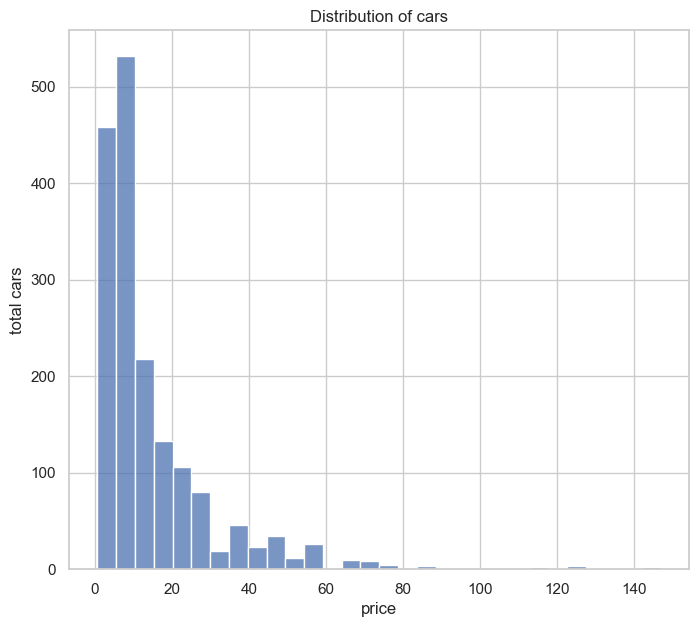

In [72]:
#Q8 Are most cars in a similar price range, or do prices vary widely?
# Converting the  price from rupees to lakhs,.
price = df["price"]/100000

plt.figure(figsize=(8,7))
sns.histplot(
    price,bins=30
)
plt.title("Distribution of cars")
plt.xlabel("price")
plt.ylabel("total cars")

plt.show()

Most cars in my dataset are priced under ₹30 lakh. Only a smaller number of cars are priced much higher. This shows that the dataset contains cars with a wide range of prices, from budget cars to luxury cars.

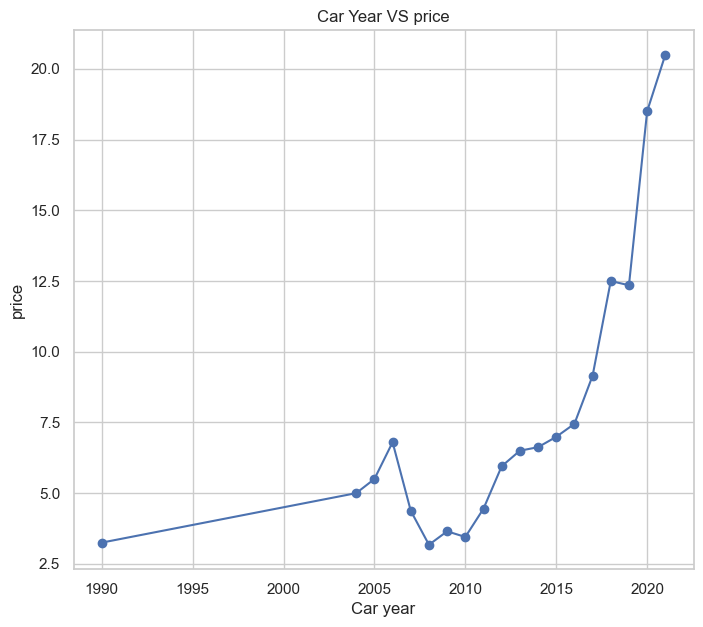

In [73]:
#Q9 Do newer cars generally sell for higher prices?
year = df.groupby("year")["price"].median()

year = (year/100000).sort_index()

plt.figure(figsize=(8,7))
plt.plot(
    year.index,
    year.values,
    marker= "o"
)
plt.title("Car Year VS price")
plt.xlabel("Car year")
plt.ylabel("price")

plt.show()

I noticed that newer cars generally have higher median prices than older cars. But prices do not increase every year. Brand, model and kilometres travelled may also affect the price.

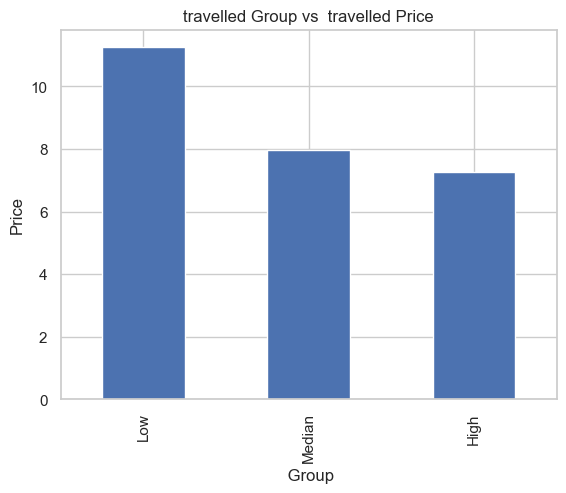

In [74]:
Distance_travelled = df.groupby("Distance_travelled",observed=False)["price"].median()
Distance_travelled = Distance_travelled/100000

Distance_travelled.plot(
    kind = "bar",
    
)
plt.title("travelled Group vs  travelled Price")
plt.xlabel(" Group")
plt.ylabel("Price")

plt.show()

I found that cars with lower travelled have higher prices in my dataset.

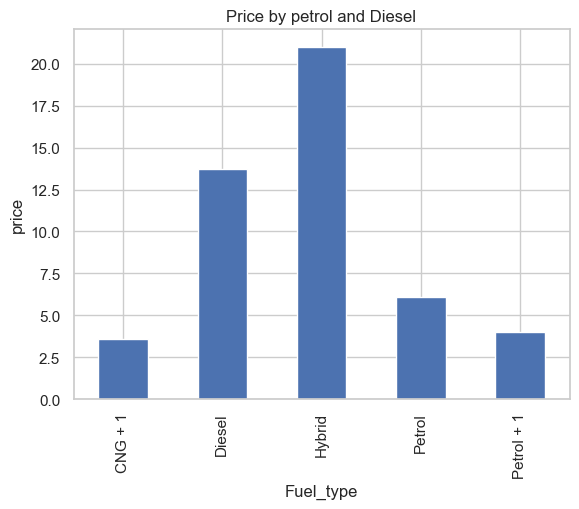

In [75]:
#Do diesel, petrol and other fuel-type cars have different selling prices?
fuel = df.groupby("fuel_type")["price"].median()
fuel = fuel/100000

fuel.plot(
    kind="bar",
    
)
plt.title("Price by petrol and Diesel")
plt.xlabel("Fuel_type")
plt.ylabel("price")

plt.show()

so here i found that diesel and petrol cars have more prices as compared to others as well as theirs counts are also more as compared to others. but here we can see hybrid cars have expensive but its only have one car which price is too more

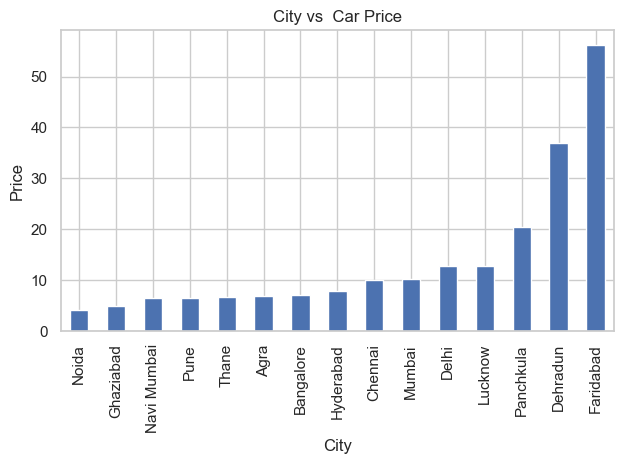

In [76]:
#Do cars listed in different cities have different selling prices?
# Find the median price for each city
city = df.groupby("city")["price"].median()


city = (city / 100000).sort_values()


city.plot(kind="bar")

plt.title("City vs  Car Price")
plt.xlabel("City")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

so here in this chart we find chennai and banglore has too much cars and their price also high but here we see faridabad has more price as compared to others but as in finding s we see faridabad has some cars which is very costlier thats why the bar is hiked up. 

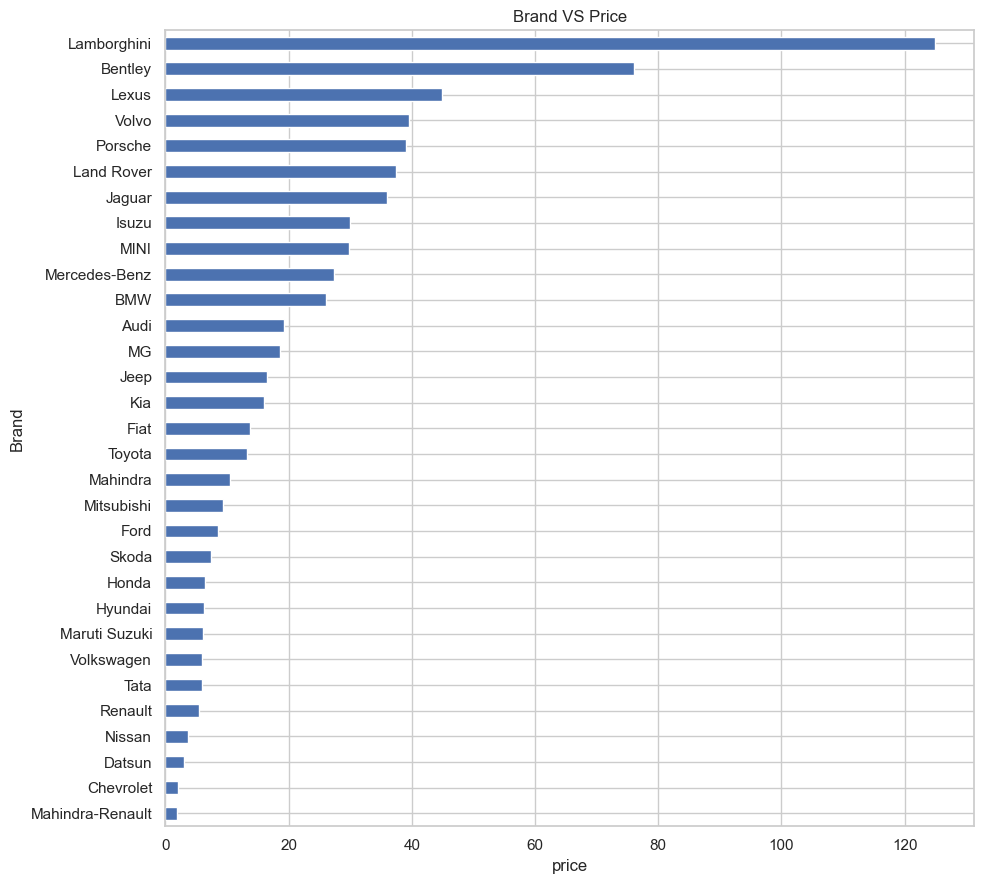

In [77]:
#Which brands have higher typical selling prices?

brand_Price = df.groupby("brand")["price"].median()
brand_Price = (brand_Price /100000).sort_values()

brand_Price.plot(kind = "barh",figsize=(10,9))

plt.title("Brand VS Price")
plt.xlabel("price")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

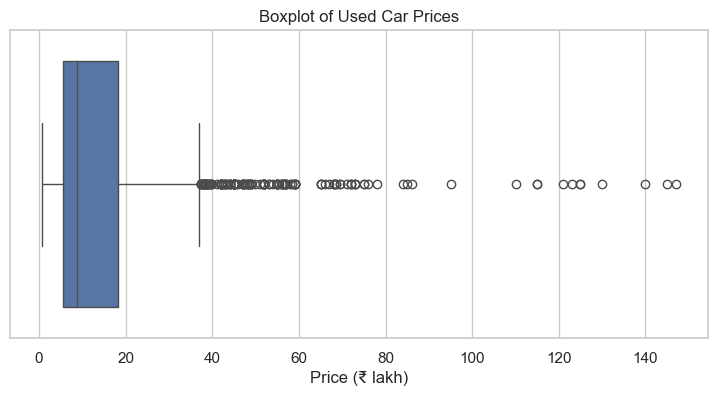

In [78]:
#Are there any unusually high or low car prices?

price_lakh = df["price"] / 100000

plt.figure(figsize=(9, 4))
sns.boxplot(x=price_lakh)

plt.title("Boxplot of Used Car Prices")
plt.xlabel("Price (₹ lakh)")
plt.show()

so as we can see most cars are in range of 0 to 20 or 30 lakh. but some cars are cost way more than Avg cars. this is outliers but we cant conclude that this is outliers cause theirs values are likely to be more than others brands

Now USing THis CLeaned Dataset for preNow Using Regression Model predict the selling price of a used car.

In [79]:
# Input features
X = df[[
    "year",
    "brand",
    "model_name",
    "distance_travelled(kms)",
    "fuel_type",
    "city"
]]

# Target column
y = df["price"]

In [80]:
# We are using train test split for splting data to train and testing our model. will bw keeping 80%, 20% rule. 
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

#So in this dataset ther are total 6 columns 2 of them are in numerical and 4 of them contain text.So we need to convert text into numericals to make predictions we using OneHotEncoder we will convert text into numericals
numerical_value = ["year","distance_travelled(kms)"]
text_value = ["brand","model_name","fuel_type","city"]

#So in this dataset ther are total 6 columns 2 of them are in numerical and 4 of them contain text . so we need to convert text into numericals to make predictions we using OneHotEncoder we will convert text into numericals

In [81]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("texts_V",OneHotEncoder(handle_unknown = "ignore",sparse_output = False),text_value)
    ],
    remainder = "passthrough"
)
# so here we using fit_transform to gve to x_train . also for test set we using data X_train assien data
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print(X_train.shape)
print(X_test.shape)
# so now we have converted all the etxt into int

(1380, 214)
(345, 214)


In [82]:
#now we are creating dummy model to check predictions to compare with train model.
# importing the basic lib for predictions
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# so here we using median to make predictions cause as we seen mean would give most right skiewd values but median gives middle values which is best for predictions
baseline_model = DummyRegressor(strategy = "median")

baseline_model.fit(X_train,y_train)

baseline_model_prediction = baseline_model.predict(X_test)

print("baseline_model_prediction: " ,baseline_model_prediction[:10])

baseline_mae = mean_absolute_error(y_test,baseline_model_prediction)
print("baseline MAE: ",round(baseline_mae/100000,2),"lakh")

baseline_model_prediction:  [842500. 842500. 842500. 842500. 842500. 842500. 842500. 842500. 842500.
 842500.]
baseline MAE:  10.92 lakh


In [83]:
#The baseline always predicted ₹8.425 lakh. now we are training Linear model to get predictions to get as lower than baseline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

linear_model = LinearRegression()

linear_model.fit(X_train,y_train)
linear_model_prediction = linear_model.predict(X_test)
linear_mae = mean_absolute_error(y_test,linear_model_prediction)

print("linear_model_prediction: ",linear_model_prediction[:5] )
print("linear_model_prediction: ",round(linear_mae/100000,2),"lakh")

linear_model_prediction:  [  62838.07514954 1061133.60227221  651555.89654911  978665.21093577
 1965945.2089355 ]
linear_model_prediction:  4.5 lakh


across our 345 test cars, the average absolute difference between the predicted price and actual price is ₹4.50 lakh. so linear model is better than baseline cause its difference of 6.42 lakhs

In [84]:
# Compare actual price with predicted price
import pandas as pd

compare = pd.DataFrame({
    "Actual_price": y_test.to_numpy() / 100000,
    "Predicted_price": linear_model_prediction / 100000
})

# Add the error as a new column
compare["Absolute_Error"] = (
    compare["Actual_price"] - compare["Predicted_price"]
).abs()

compare.head(5).round(2)

,Actual_price,Predicted_price,Absolute_Error
0,3.65,0.63,3.02
1,11.95,10.61,1.34
2,5.75,6.52,0.77
3,9.00,9.79,0.79
4,16.75,19.66,2.91


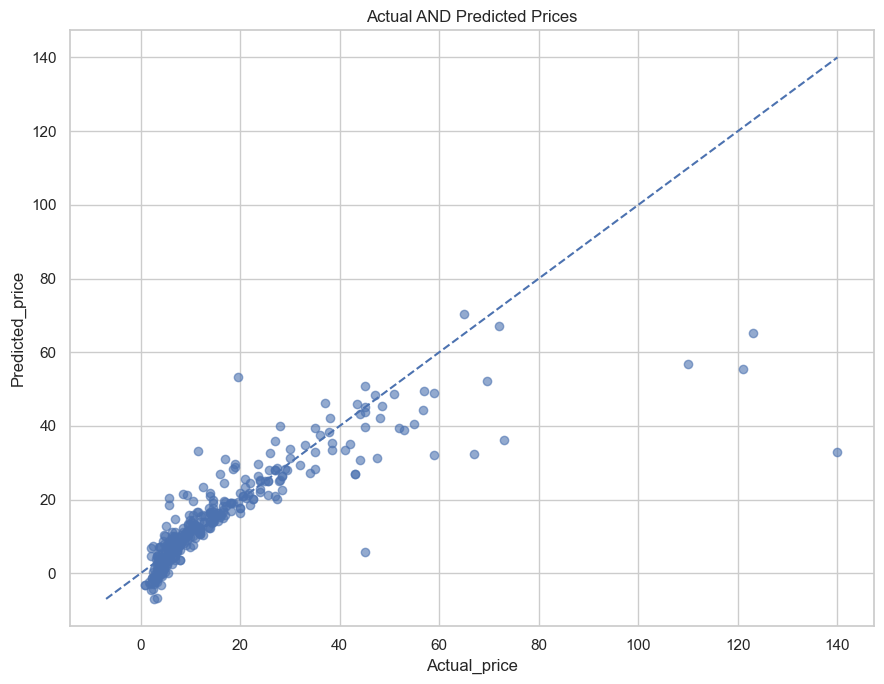

In [85]:
# Draw the chart to see comparison
plt.figure(figsize=(9,7))
plt.scatter(
    compare["Actual_price"],
    compare["Predicted_price"],
    alpha = 0.6
)
minimum = min(
    compare["Actual_price"].min(),
    compare["Predicted_price"].min()
)
maximum = max(
    compare["Actual_price"].max(),
    compare["Predicted_price"].max()
)
plt.plot(
    [minimum,maximum],
    [minimum,maximum],
    linestyle = "--"
)
plt.title("Actual AND Predicted Prices")
plt.xlabel("Actual_price")
plt.ylabel("Predicted_price")
plt.tight_layout()
plt.show()

most predictions are close to line which is good predictions . soome are way to underpreditions by residual and some are overpredictions

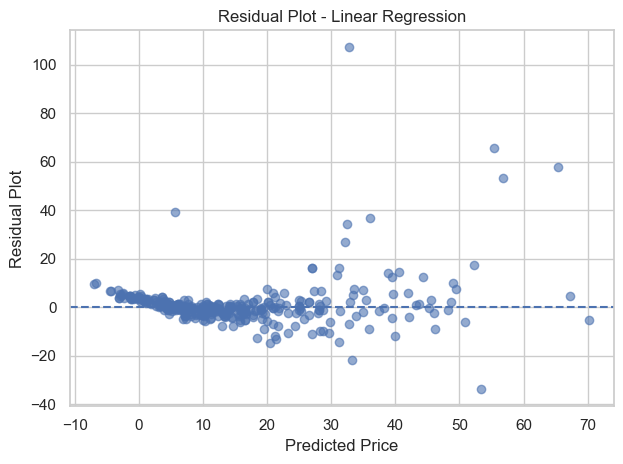

In [86]:
compare["Residual"] = (
    compare["Actual_price"] - compare["Predicted_price"]
    
)
plt.scatter(
    compare["Predicted_price"],
    compare["Residual"],
    alpha = 0.6
)
plt.axhline(y=0,linestyle="--")

plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted Price")
plt.ylabel("Residual Plot")
plt.tight_layout()
plt.show()

i can see points are scatter near to zero. but there are some ponts that are away from xero. also .but most points are near xeros

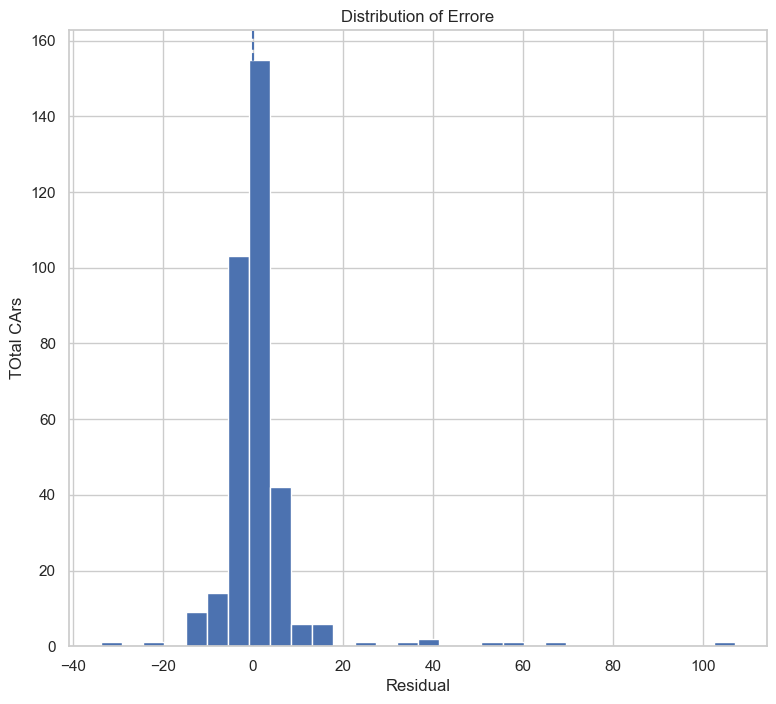

In [87]:
#histogram shows us how many errors are small, large, positive, or negative.
plt.figure(figsize=(9,8))
plt.hist(compare["Residual"],bins = 30)
plt.axvline(x=0,linestyle="--")

plt.title("Distribution of Errore")
plt.xlabel("Residual")
plt.ylabel("TOtal CArs")

plt.show()

so here i can see most erros occurs are far from zero. so this plot shows most points are near zeros.  are shows there are still cars are far more expensive

now we checking this predictions will be checking with more evalutions.(RMSE,R2 Squared)to compare how model is gives more predictions using evalutions

In [88]:
#Now We are evaluates the model with MAE,RMSE,R2 Squared metrices.
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

mae = mean_absolute_error(y_test,linear_model_prediction)
rmse = np.sqrt(mean_squared_error(y_test,linear_model_prediction))
r2_score = r2_score(y_test,linear_model_prediction)

print("MAE: ",round(mae / 100000,2),"lakh")
print("RMSE: ",round(rmse /100000,2),"lakh")
print("R2_SCORE: ",round(r2_score,3))


MAE:  4.5 lakh
RMSE:  10.13 lakh
R2_SCORE:  0.694


Now we are checking how can we get complex patterns using ramdom forest and gradient Boosting regresor so we can predict used car prices better.

In [89]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

RF_model = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42
)
RF_model.fit(X_train,y_train)
RF_model_predictions = RF_model.predict(X_test)

RF_mae = mean_absolute_error(y_test,RF_model_predictions)
RF_rmse = np.sqrt(mean_squared_error(y_test,RF_model_predictions))
RF_r2_score = r2_score(y_test,RF_model_predictions)

print("RF_MAE: ",round(RF_mae/100000,2),"lakh")
print("RF_RMSE: ",round(RF_rmse/100000,2),"lakh")
print("RF_R2_SCORE: ",round(RF_r2_score,3))


RF_MAE:  3.12 lakh
RF_RMSE:  9.62 lakh
RF_R2_SCORE:  0.725


now checking using gradinet boosting regressor

In [90]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

GB_model = GradientBoostingRegressor(
    n_estimators = 100,
    learning_rate = 0.1,
    random_state = 42
)
GB_model.fit(X_train, y_train)

GB_predictions = GB_model.predict(X_test)

GB_mae = mean_absolute_error(y_test, GB_predictions)
GB_rmse = np.sqrt(mean_squared_error(y_test, GB_predictions))
GB_r2 = r2_score(y_test, GB_predictions)

print("GB_MAE:", round(GB_mae / 100000, 2), "lakh")
print("GB_RMSE:", round(GB_rmse / 100000, 2), "lakh")
print("GB_R2_SCORE:", round(GB_r2, 3))

GB_MAE: 4.75 lakh
GB_RMSE: 10.43 lakh
GB_R2_SCORE: 0.676


So as we compare all three models Random Forest Regressor gives the best and Low Predictions amongs 3. so we can conclude that RF model is the one to predicts best model

In [91]:
import joblib

final_model = {
    "model":RF_model,
    "preprocessor":preprocessor
}
joblib.dump(final_model,"Used-Car_Price_Model.pkl")
print("Final Model Saved Succesfully")

Final Model Saved Succesfully


here we used job librery to save our final model (RandomForestRegressor) and named it as Used-Car_Price_Model.pkl and later we can use this only using this name

Now lets check that our model is working with this name load them directly without doing all from start. here we load model using joblib.load to check this model works or not

In [92]:
import joblib
import numpy as np

saved_artifact = joblib.load("Used-Car_Price_Model.pkl")

loaded_model = saved_artifact["model"]

loaded_predictions = loaded_model.predict(X_test)

print("First 5 predictions:", loaded_predictions[:5])

print(
    "Predictions match:",
    np.allclose(RF_model_predictions, loaded_predictions)
)

First 5 predictions: [ 388750.  688480.  674990.  902700. 1310820.]
Predictions match: True


In [93]:
feature_columns = [
    "year",
    "brand",
    "model_name",
    "distance_travelled(kms)",
    "fuel_type",
    "city"
]

sample_car = df[feature_columns].iloc[[0]]

sample_car_processed = saved_artifact["preprocessor"].transform(sample_car)

sample_prediction = saved_artifact["model"].predict(sample_car_processed)

print(sample_car)
print("Predicted price:", round(sample_prediction[0] / 100000, 2), "lakh")

   year  brand model_name  distance_travelled(kms) fuel_type    city
0  2016  Honda       Brio                   9680.0    Petrol  Mumbai
Predicted price: 5.01 lakh


Now we are use the saved model and preprocessor together to predict a car price from raw car details. This model was trained using processed data and its giving the matches from DATASETS. 

## Final Conclusion

I built a used-car price prediction model using regression.

I compared three models: Linear Regression, Random Forest, and Gradient Boosting.

Random Forest performed best among the three models tested.

- MAE: ₹3.12 lakh
- RMSE: ₹9.62 lakh
- R² Score: 0.725

The model uses the car's year, brand, model, kilometres driven, fuel type, and city to predict its price.

The results show that Random Forest performed better than the other tested models on the test dataset.
